# Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial
## Fase 1: Planteamiento del Problema, Descripción y EDA (Entregable 1 - 20%)

* **Estudiante:** Yerson León Montañez
* **Correo Institucional:** yeleon36@unisalle.edu.co
* **Institución:** Universidad de La Salle — Facultad de Ingeniería / Maestría en Inteligencia Artificial
* **Asignatura:** Ciencia de Datos
* **Docente:** Fabián Camilo Castro Riveros
* **Periodo Académico:** 20 de octubre – 28 de noviembre de 2026


---
## 1. Formulación del Problema y Objetivos del Negocio

### 1.1. Contextualización del Dominio e Impacto
En la industria de telecomunicaciones, la deserción o pérdida de clientes (*Customer Churn*) representa uno de los mayores desafíos operacionales y financieros. Adquirir un nuevo suscriptor puede costar entre 5 y 25 veces más que retener a uno existente. La tasa de abandono no solo erosiona el flujo de caja recurrente (*Monthly Recurring Revenue* - MRR), sino que también refleja fallas de satisfacción en la oferta tecnológica, soporte posventa o competitividad tarifaria.

El desarrollo de una solución analítica integral que diagnostique los factores determinantes de la fuga, anticipe probabilísticamente el abandono y segmente a los clientes según su patrón de consumo y valor de vida útil (*Lifetime Value* - LTV), permite a la organización desplegar estrategias proactivas de retención de alto impacto y asignación óptima de recursos.

### 1.2. Preguntas de Investigación
* **Pregunta Principal:**
  * ¿Cuáles son los patrones de comportamiento, características de suscripción y factores estructurales que determinan la probabilidad de deserción de los clientes de telecomunicaciones y cómo pueden modelarse para optimizar la retención y predecir el valor monetario del cliente?
* **Preguntas Secundarias:**
  1. ¿En qué medida influye la duración del contrato (mensual vs. anual) y el método de pago en la tasa de deserción del usuario?
  2. ¿Existe una relación estadísticamente significativa entre la adopción de servicios complementarios de valor agregado (soporte técnico, seguridad en línea) y la lealtad del cliente?
  3. ¿Cómo interactúan los cargos mensuales (`MonthlyCharges`) y la antigüedad (`tenure`) en la determinación del valor total facturado (`TotalCharges`), y cuáles son los umbrales financieros donde se concentra el mayor riesgo de deserción?

### 1.3. Objetivos del Proyecto (Formato SMART)
* **Objetivo General:**
  * Desarrollar y validar un sistema analítico predictivo y prescriptivo de Ciencia de Datos sobre el ciclo de vida del cliente de telecomunicaciones, integrando modelos de regresión para estimar cargos acumulados, algoritmos de clasificación supervisada para predecir la fuga (Churn) y técnicas no supervisadas de clustering para la segmentación estratégica, culminando en un dashboard interactivo funcional en el periodo del 20 de octubre al 28 de noviembre de 2026.
* **Objetivos Específicos:**
  1. **Específico 1 (EDA y Calidad):** Caracterizar exhaustivamente la distribución estadística, calidad e interdependencias de las 21 variables del conjunto de datos Telco mediante análisis univariado, bivariado ($\chi^2$, correlaciones de Pearson/Spearman) y diagnóstico de valores atípicos y faltantes antes del 01 de noviembre de 2026.
  2. **Específico 2 (Modelado Predictivo y Redes Neuronales):** Implementar y comparar modelos de regresión regularizada (Lasso/Ridge/Random Forest), clasificación (KNN, Random Forest, SVM/XGBoost) y un Perceptrón Multicapa (MLP) en PyTorch, alcanzando un $R^2 \ge 0.80$ en regresión y un $F_1\text{-score} \ge 0.78$ en la clase minoritaria de deserción antes del 22 de noviembre de 2026.
  3. **Específico 3 (Puesta en Producción e Interpretabilidad):** Diseñar e implementar un dashboard interactivo en Streamlit con inferencia en vivo, visualización de clústeres dimensionales e interpretación de variables críticas con valores SHAP antes del 28 de noviembre de 2026.


---
## 2. Configuración del Entorno y Carga de Datos
Carga de librerías esenciales, verificación del entorno y lectura del dataset crudo.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustes de visualización
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

# Ruta de datos
DATA_PATH = os.path.join('..', 'data', 'raw', 'telco_customer_churn.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'raw', 'telco_customer_churn.csv')

df_raw = pd.read_csv(DATA_PATH)
print(f"Dimensiones del dataset crudo: {df_raw.shape[0]} registros, {df_raw.shape[1]} columnas.")
df_raw.head(3)


Dimensiones del dataset crudo: 7043 registros, 21 columnas.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes


---
## 3. Ficha Técnica y Diccionario de Variables

### 3.1. Ficha Técnica del Dataset
* **Nombre oficial:** Telco Customer Churn (IBM Business Analytics / Kaggle)
* **Repositorio de Origen:** Kaggle / IBM Community
* **URL de Acceso:** [https://www.kaggle.com/datasets/blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
* **Fecha de Extracción:** 28 de octubre de 2026
* **Tipo de Licencia:** Creative Commons / Apache 2.0 (Uso libre y público sin restricciones)
* **Volumen:** 7,043 instancias y 21 atributos (cumple ampliamente el requerimiento de $\ge 600$ filas y $\ge 5$ variables mixtas).

### 3.2. Inspección de Tipos y Estructura


In [2]:
# Resumen estructural de variables
df_info = pd.DataFrame({
    'Tipo Dtype': df_raw.dtypes,
    'Valores Únicos': df_raw.nunique(),
    'Ejemplo': [df_raw[col].iloc[0] for col in df_raw.columns]
})
df_info


,Tipo Dtype,Valores Únicos,Ejemplo
customerID,object,7043,7590-VHVEG
gender,object,2,Female
SeniorCitizen,int64,2,0
Partner,object,2,Yes
Dependents,object,2,No
tenure,int64,73,1
PhoneService,object,2,No
MultipleLines,object,3,No phone service
InternetService,object,3,DSL
OnlineSecurity,object,3,No


---
## 4. Diagnóstico Exhaustivo de Calidad de Datos

En esta sección se auditan:
1. Registros duplicados globales y de la clave primaria (`customerID`).
2. Detección de nulos explícitos y valores faltantes encubiertos (como espacios en blanco).
3. Mecanismos de falta estadística (MCAR, MAR, MNAR) para la variable `TotalCharges`.


In [3]:
# 1. Duplicados
total_dup = df_raw.duplicated().sum()
id_dup = df_raw['customerID'].duplicated().sum()
print(f"Duplicados totales de fila: {total_dup}")
print(f"Duplicados en identificador 'customerID': {id_dup}")

# 2. Detección de valores faltantes encubiertos
missing_counts = {}
for col in df_raw.columns:
    if col == 'TotalCharges':
        n_spaces = (df_raw[col].astype(str).str.strip() == '').sum()
        missing_counts[col] = n_spaces
    else:
        missing_counts[col] = df_raw[col].isna().sum()

missing_df = pd.DataFrame({
    'Valores_Faltantes': missing_counts.values(),
    'Porcentaje_Falta (%)': [round(v / len(df_raw) * 100, 4) for v in missing_counts.values()]
}, index=missing_counts.keys())

print("\nVariables con registros faltantes detectadas:")
display(missing_df[missing_df['Valores_Faltantes'] > 0])


Duplicados totales de fila: 0
Duplicados en identificador 'customerID': 0

Variables con registros faltantes detectadas:


,Valores_Faltantes,Porcentaje_Falta (%)
TotalCharges,11,0.156


### Análisis del Mecanismo de Falta en `TotalCharges`
Observemos los registros donde `TotalCharges` presenta espacios en blanco:


In [4]:
blank_total_mask = df_raw['TotalCharges'].astype(str).str.strip() == ''
display(df_raw.loc[blank_total_mask, ['customerID', 'tenure', 'Contract', 'MonthlyCharges', 'TotalCharges', 'Churn']])


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.550,,No
753,3115-CZMZD,0,Two year,20.250,,No
936,5709-LVOEQ,0,Two year,80.850,,No
1082,4367-NUYAO,0,Two year,25.750,,No
1340,1371-DWPAZ,0,Two year,56.050,,No
3331,7644-OMVMY,0,Two year,19.850,,No
3826,3213-VVOLG,0,Two year,25.350,,No
4380,2520-SGTTA,0,Two year,20.000,,No
5218,2923-ARZLG,0,One year,19.700,,No
6670,4075-WKNIU,0,Two year,73.350,,No


**Diagnóstico Técnico:**
Todos los 11 registros con `TotalCharges` faltante corresponden a clientes con `tenure == 0`. Esto indica que son suscriptores recién incorporados que aún no han cumplido su primer ciclo completo de facturación.
Por consiguiente, el mecanismo de falta es **MAR (Missing at Random)**, perfectamente condicionado a la variable observada `tenure`.


---
## 5. Análisis Exploratorio Univariado

### 5.1. Variables Cuantitativas
Calculamos medidas de tendencia central (media, mediana), dispersión (desviación estándar, IQR), rango (mínimo, máximo) y momentos estadísticos de forma:
* **Coeficiente de Asimetría de Fisher-Pearson ($g_1$):**
  $$g_1 = \frac{\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^3}{\left(\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2\right)^{3/2}}$$
* **Exceso de Curtosis ($g_2$):**
  $$g_2 = \frac{\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^4}{\left(\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2\right)^2} - 3$$


In [5]:
# Conversión segura para análisis estadístico
df_clean = df_raw.copy()
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'].replace(' ', np.nan), errors='coerce')

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

stats_list = []
for c in num_cols:
    s = df_clean[c].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    stats_list.append({
        'Variable': c,
        'N Válidos': len(s),
        'Media': s.mean(),
        'Mediana': s.median(),
        'Desv. Estándar': s.std(),
        'Q1 (P25)': q1,
        'Q3 (P75)': q3,
        'IQR': q3 - q1,
        'Mínimo': s.min(),
        'Máximo': s.max(),
        'Asimetría': stats.skew(s, bias=False),
        'Curtosis (Exceso)': stats.kurtosis(s, bias=False)
    })

pd.DataFrame(stats_list)


,Variable,N Válidos,Media,Mediana,Desv. Estándar,Q1 (P25),Q3 (P75),IQR,Mínimo,Máximo,Asimetría,Curtosis (Exceso)
0,tenure,7043,32.371,29.000,24.559,9.000,55.000,46.000,0.000,72.000,0.240,-1.387
1,MonthlyCharges,7043,64.762,70.350,30.090,35.500,89.850,54.350,18.250,118.750,-0.221,-1.257
2,TotalCharges,7032,2283.300,1397.475,2266.771,401.450,3794.738,3393.288,18.800,8684.800,0.962,-0.232


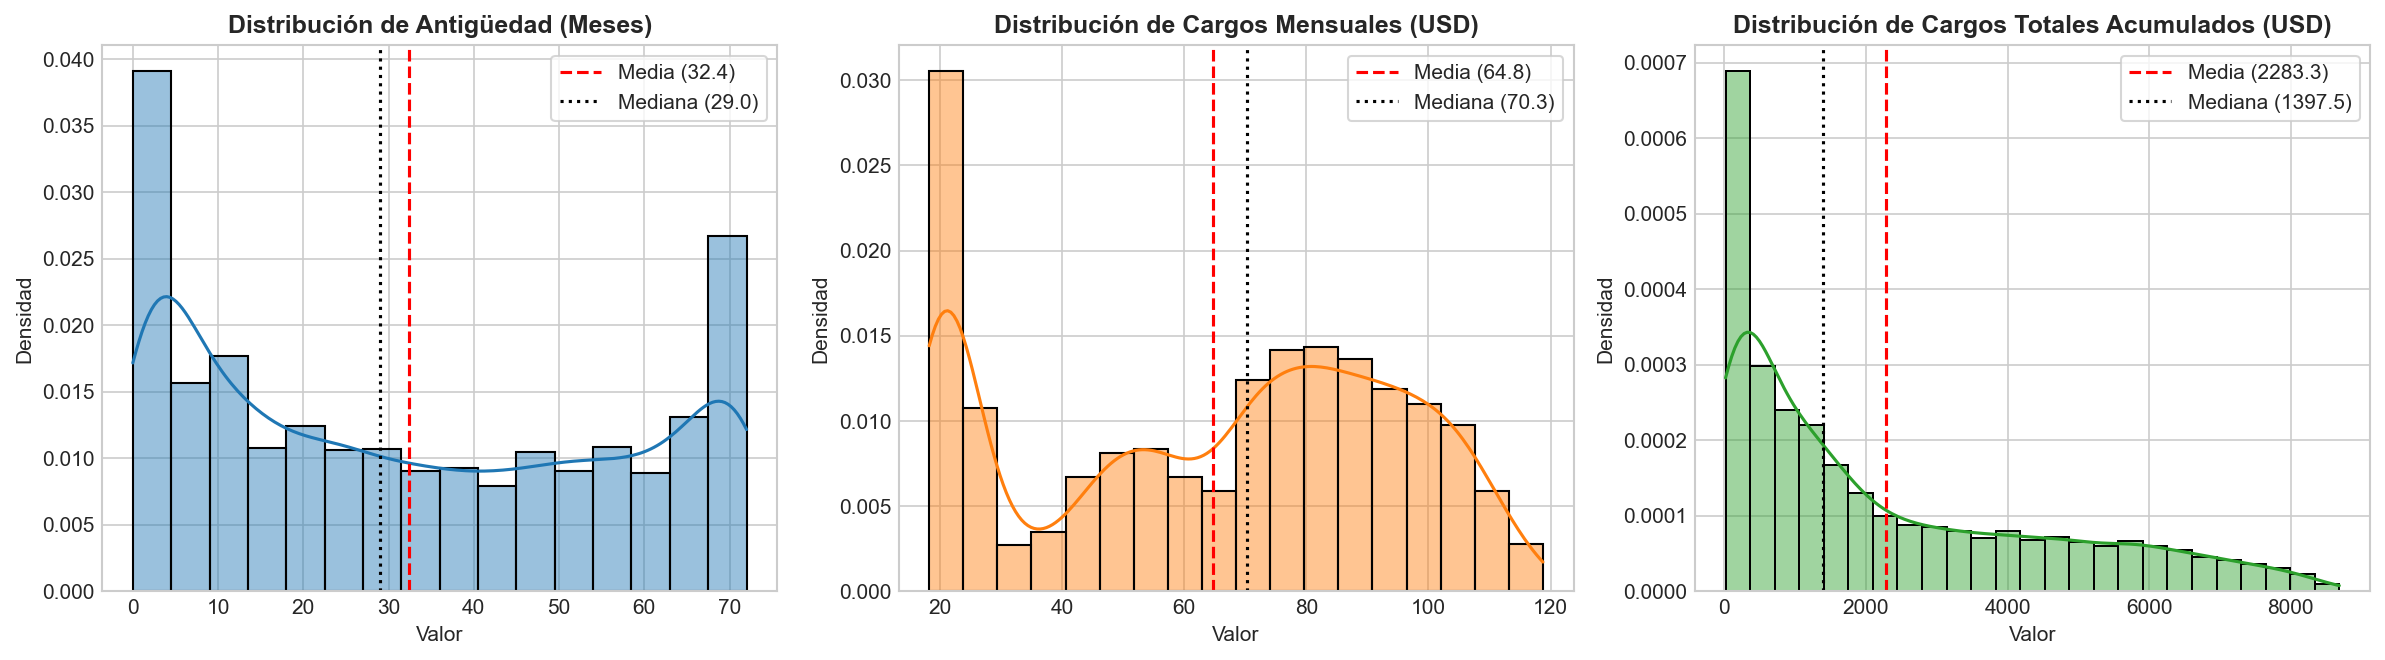

In [6]:
# Visualización de distribuciones univariadas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
col_titles = [('tenure', 'Antigüedad (Meses)'), 
              ('MonthlyCharges', 'Cargos Mensuales (USD)'), 
              ('TotalCharges', 'Cargos Totales Acumulados (USD)')]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, (col, title), color in zip(axes, col_titles, colors):
    s = df_clean[col].dropna()
    sns.histplot(s, kde=True, ax=ax, color=color, stat='density', alpha=0.45)
    ax.axvline(s.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Media ({s.mean():.1f})')
    ax.axvline(s.median(), color='black', linestyle=':', linewidth=1.5, label=f'Mediana ({s.median():.1f})')
    ax.set_title(f'Distribución de {title}', fontweight='bold')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Densidad')
    ax.legend(frameon=True)

plt.tight_layout()
plt.show()


### 5.2. Variables Cualitativas y Variable Objetivo `Churn`
Analizamos las frecuencias absolutas ($n$) y relativas (%) para identificar posibles desbalances de clase.


Distribución de la variable objetivo 'Churn':


,Frecuencia Absoluta (n),Frecuencia Relativa (%)
Churn,,
No,5174,73.463
Yes,1869,26.537


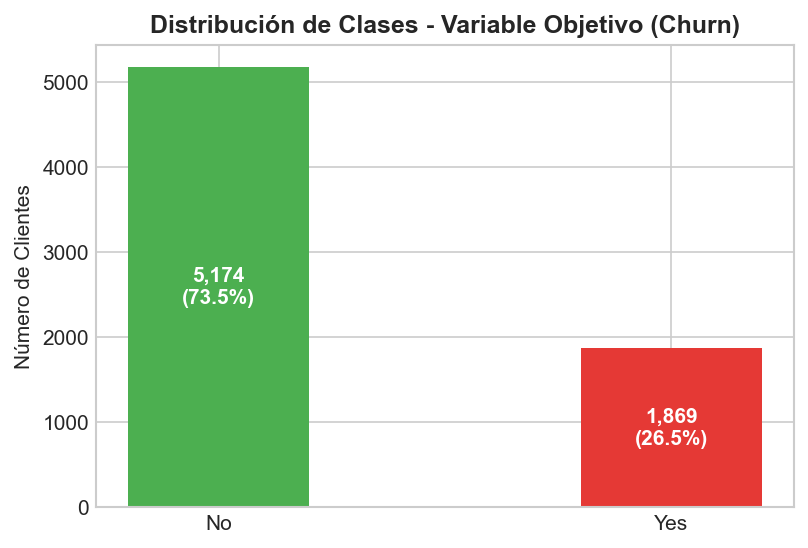

In [7]:
# Distribución de la variable objetivo Churn
churn_freq = df_clean['Churn'].value_counts()
churn_pct = df_clean['Churn'].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    'Frecuencia Absoluta (n)': churn_freq,
    'Frecuencia Relativa (%)': churn_pct
})
print("Distribución de la variable objetivo 'Churn':")
display(churn_summary)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_summary.index, churn_summary['Frecuencia Absoluta (n)'], color=['#4CAF50', '#E53935'], width=0.4)
ax.set_title('Distribución de Clases - Variable Objetivo (Churn)', fontweight='bold')
ax.set_ylabel('Número de Clientes')
for bar in bars:
    height = bar.get_height()
    pct = height / len(df_clean) * 100
    ax.text(bar.get_x() + bar.get_width()/2., height/2, f'{height:,}\n({pct:.1f}%)',
            ha='center', va='center', color='white', fontweight='bold')
plt.show()


---
## 6. Detección de Valores Atípicos (Outliers)

Se aplican simultáneamente dos metodologías formales:
1. **Regla de Tukey (Rango Intercuartílico - IQR):**
   $$[Q_1 - 1.5 \times IQR, \quad Q_3 + 1.5 \times IQR]$$
2. **Criterio de Estandarización ($Z$-score):**
   $$|Z_i| = \left|\frac{x_i - \mu}{\sigma}\right| > 3$$


In [8]:
outlier_audit = []
for c in num_cols:
    s = df_clean[c].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    out_iqr = s[(s < lim_inf) | (s > lim_sup)]
    
    z = np.abs(stats.zscore(s))
    out_z = s[z > 3.0]
    
    outlier_audit.append({
        'Variable': c,
        'Límite Inf IQR': lim_inf,
        'Límite Sup IQR': lim_sup,
        'Atípicos IQR (n)': len(out_iqr),
        'Atípicos IQR (%)': len(out_iqr) / len(s) * 100,
        'Atípicos |Z|>3 (n)': len(out_z),
        'Atípicos |Z|>3 (%)': len(out_z) / len(s) * 100
    })

pd.DataFrame(outlier_audit)


,Variable,Límite Inf IQR,Límite Sup IQR,Atípicos IQR (n),Atípicos IQR (%),Atípicos |Z|>3 (n),Atípicos |Z|>3 (%)
0,tenure,-60.000,124.000,0,0.000,0,0.000
1,MonthlyCharges,-46.025,171.375,0,0.000,0,0.000
2,TotalCharges,-4688.481,8884.669,0,0.000,0,0.000


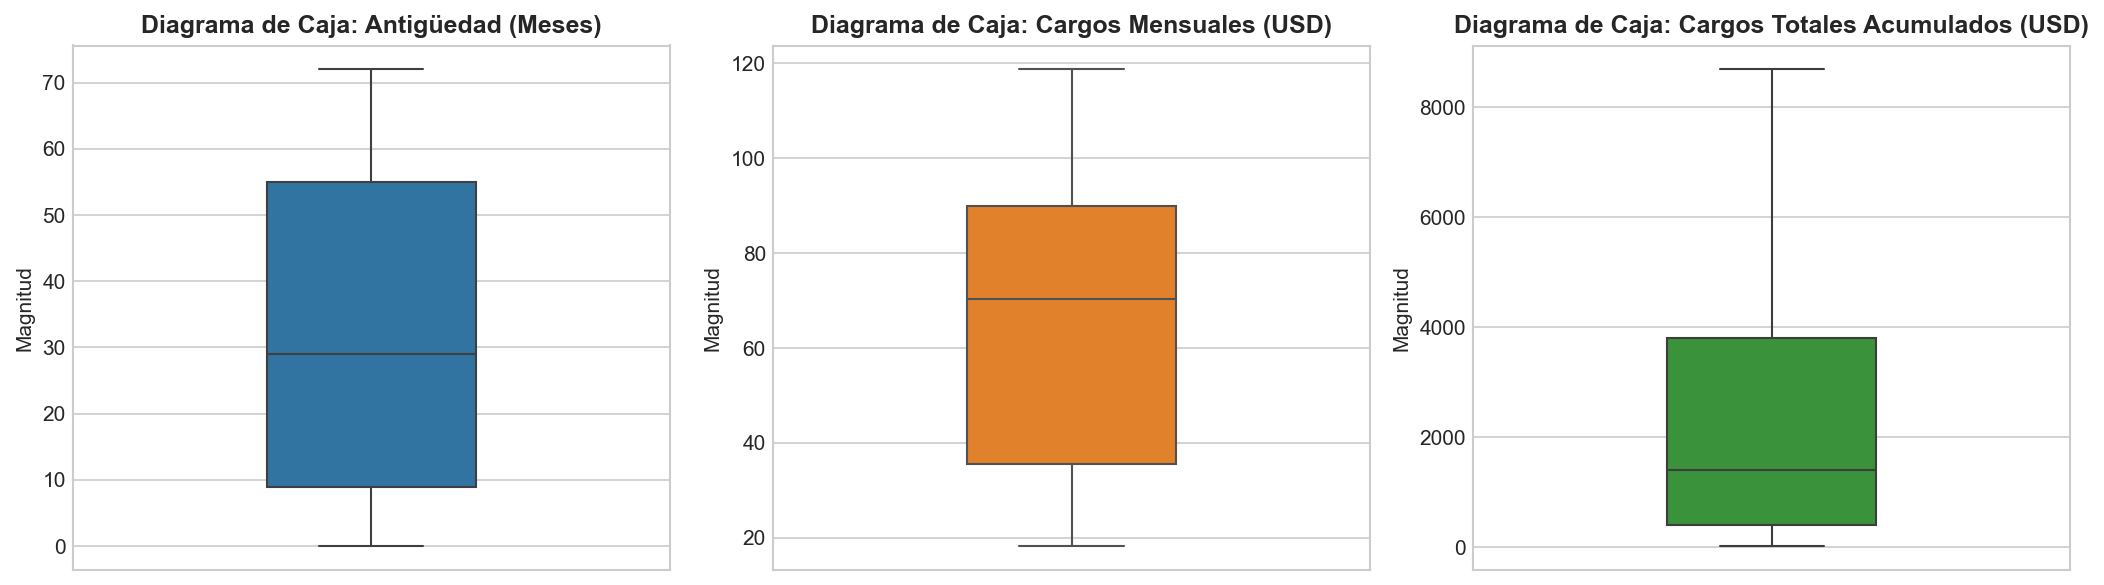

In [9]:
# Diagramas de caja (Boxplots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, title), color in zip(axes, col_titles, colors):
    sns.boxplot(y=df_clean[col], ax=ax, color=color, width=0.35, fliersize=4)
    ax.set_title(f'Diagrama de Caja: {title}', fontweight='bold')
    ax.set_ylabel('Magnitud')
plt.tight_layout()
plt.show()


---
## 7. Análisis Bivariado y Multivariado

### 7.1. Correlación Numérica: Pearson vs. Spearman
Examinamos la correlación lineal paramétrica (Pearson) y monótona de rangos no paramétrica (Spearman) entre las variables numéricas:


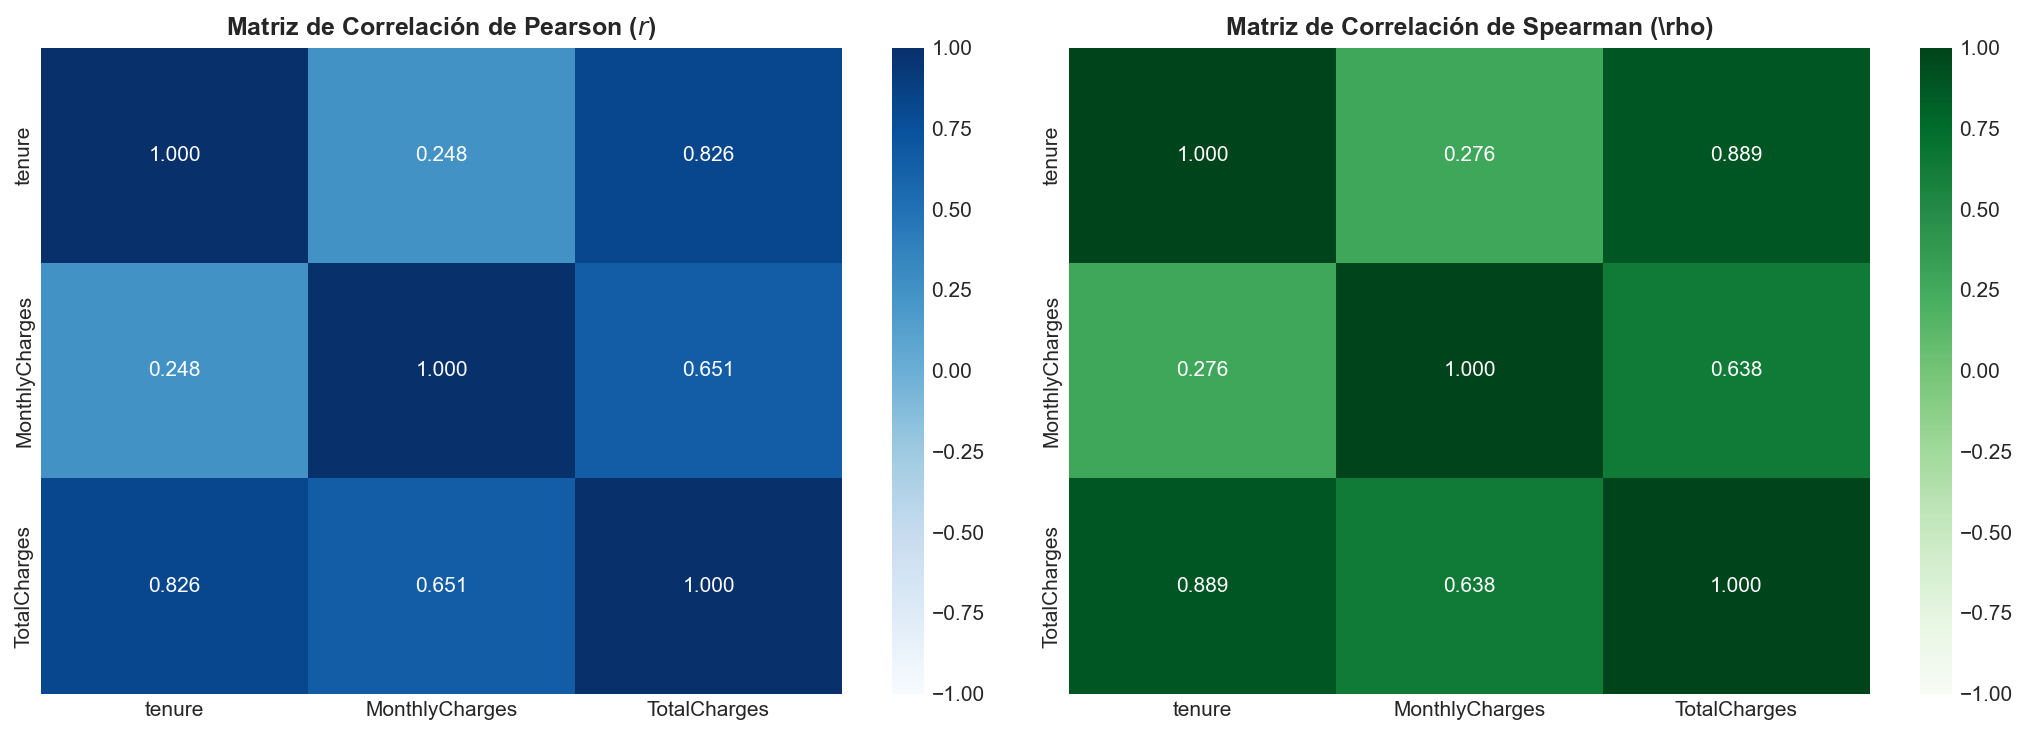

In [10]:
corr_pearson = df_clean[num_cols].corr(method='pearson')
corr_spearman = df_clean[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr_pearson, annot=True, fmt='.3f', cmap='Blues', ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('Matriz de Correlación de Pearson ($r$)', fontweight='bold')

sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='Greens', ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title('Matriz de Correlación de Spearman (\\rho)', fontweight='bold')
plt.tight_layout()
plt.show()


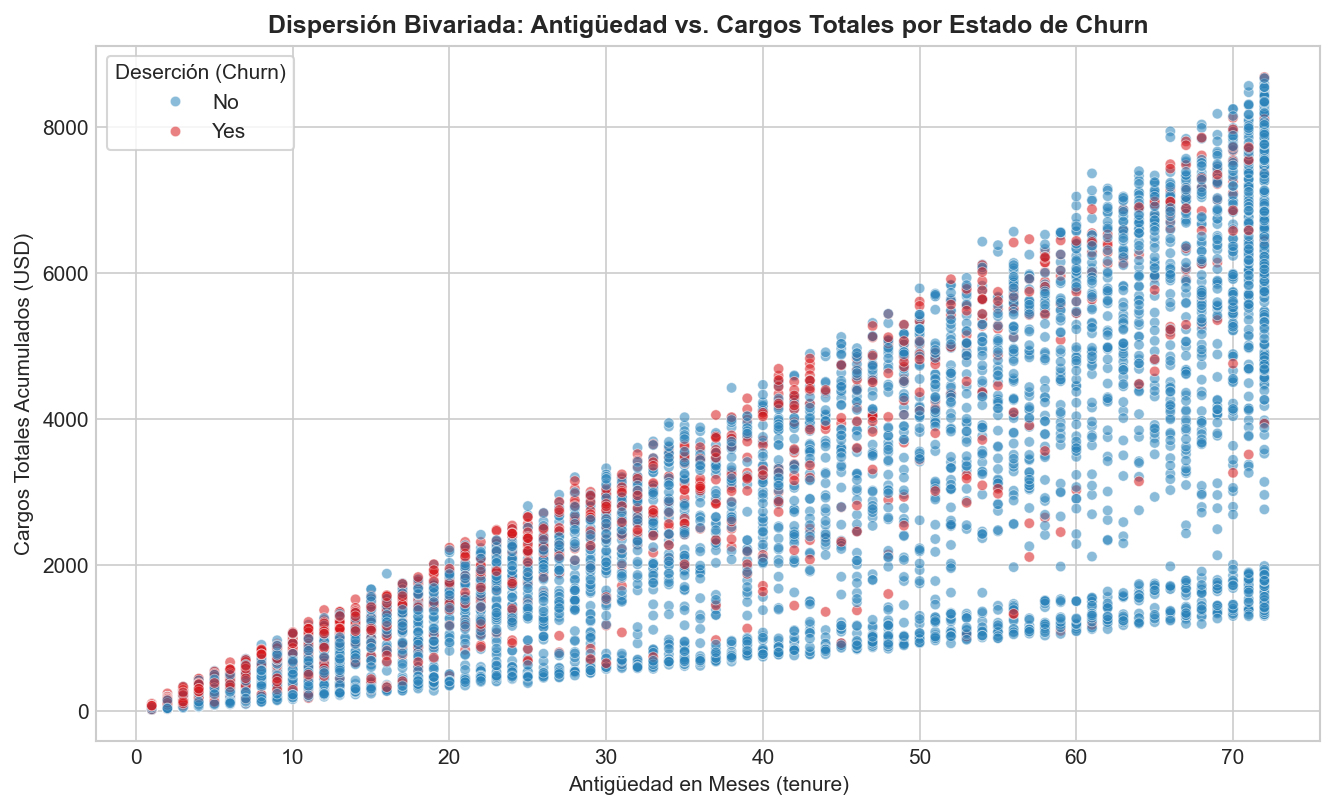

In [11]:
# Gráfico de dispersión tenure vs TotalCharges condicionado por Churn
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(
    data=df_clean, x='tenure', y='TotalCharges', hue='Churn',
    palette={'No': '#2b83ba', 'Yes': '#d7191c'}, alpha=0.55, s=25, ax=ax
)
ax.set_title('Dispersión Bivariada: Antigüedad vs. Cargos Totales por Estado de Churn', fontweight='bold')
ax.set_xlabel('Antigüedad en Meses (tenure)')
ax.set_ylabel('Cargos Totales Acumulados (USD)')
ax.legend(title='Deserción (Churn)', frameon=True)
plt.tight_layout()
plt.show()


### 7.2. Pruebas de Independencia $\chi^2$ y Coeficiente $V$ de Cramér
Evaluamos la significancia estadística y la intensidad de asociación entre cada atributo cualitativo y la deserción (`Churn`):
* **Estadístico $\chi^2$:**
  $$\chi^2 = \sum_{i=1}^r \sum_{j=1}^c \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$
* **$V$ de Cramér:**
  $$V = \sqrt{\frac{\chi^2}{n \cdot \min(r-1, c-1)}}$$


In [12]:
cat_features = [
    'Contract', 'OnlineSecurity', 'TechSupport', 'InternetService',
    'PaymentMethod', 'OnlineBackup', 'DeviceProtection', 'StreamingMovies',
    'StreamingTV', 'PaperlessBilling', 'Dependents', 'SeniorCitizen',
    'Partner', 'MultipleLines', 'PhoneService', 'gender'
]

chi2_results = []
for var in cat_features:
    contingency = pd.crosstab(df_clean[var], df_clean['Churn'])
    chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    min_dim = min(contingency.shape) - 1
    v = np.sqrt(chi2 / (n * min_dim))
    chi2_results.append({
        'Variable': var,
        'Estadístico χ²': chi2,
        'Grados Libertad': dof,
        'p-valor': p_val,
        'V de Cramér': v,
        'Significativo (α=0.05)': 'Sí' if p_val < 0.05 else 'No'
    })

df_chi2_summary = pd.DataFrame(chi2_results).sort_values(by='V de Cramér', ascending=False)
df_chi2_summary


,Variable,Estadístico χ²,Grados Libertad,p-valor,V de Cramér,Significativo (α=0.05)
0,Contract,1184.597,2,0.000,0.410,Sí
1,OnlineSecurity,849.999,2,0.000,0.347,Sí
2,TechSupport,828.197,2,0.000,0.343,Sí
3,InternetService,732.310,2,0.000,0.322,Sí
4,PaymentMethod,648.142,3,0.000,0.303,Sí
5,OnlineBackup,601.813,2,0.000,0.292,Sí
6,DeviceProtection,558.419,2,0.000,0.282,Sí
7,StreamingMovies,375.661,2,0.000,0.231,Sí
8,StreamingTV,374.204,2,0.000,0.231,Sí
9,PaperlessBilling,258.278,1,0.000,0.191,Sí


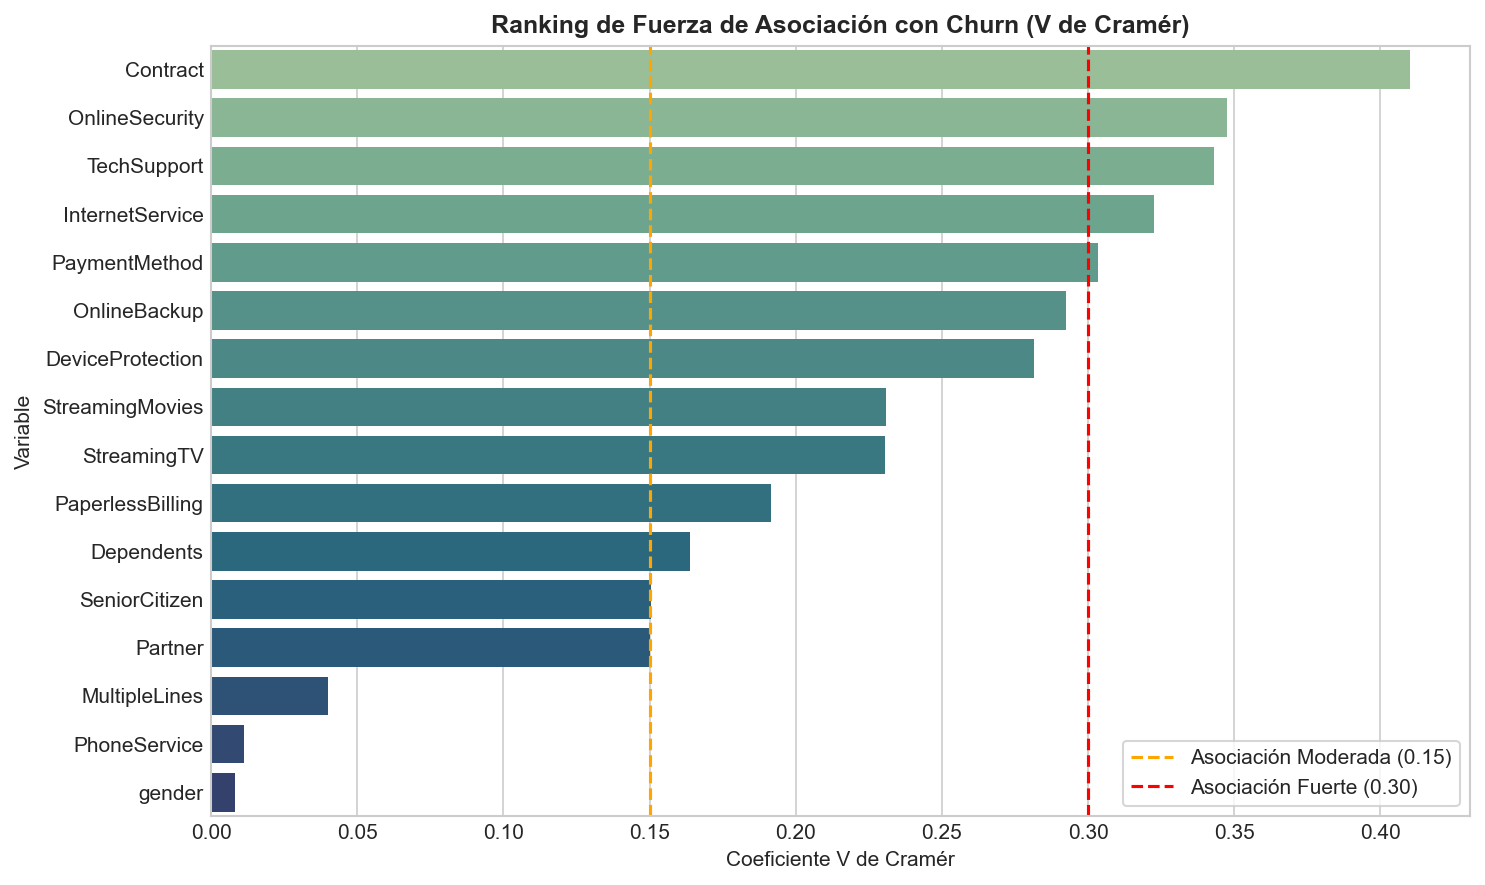

In [13]:
# Gráfico de barras de V de Cramér
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_chi2_summary, x='V de Cramér', y='Variable', hue='Variable', palette='crest', legend=False, ax=ax)
ax.axvline(0.15, color='orange', linestyle='--', label='Asociación Moderada (0.15)')
ax.axvline(0.30, color='red', linestyle='--', label='Asociación Fuerte (0.30)')
ax.set_title('Ranking de Fuerza de Asociación con Churn (V de Cramér)', fontweight='bold')
ax.set_xlabel('Coeficiente V de Cramér')
ax.legend(frameon=True, loc='lower right')
plt.tight_layout()
plt.show()


---
## 8. Conclusiones Estadísticas y Hoja de Ruta para la Fase 2

1. **Hallazgo de Calidad:**
   * La base no presenta duplicados. La variable `TotalCharges` presenta exactamente 11 registros con espacios en blanco ($0.156\%$ del dataset), todos correspondientes a `tenure == 0`.
   * En la **Fase 2**, estos valores deben imputarse de manera justificada a cero (`TotalCharges = 0.0`), ya que el cliente no ha acumulado facturación, preservando los registros sin pérdida de información ni distorsión.
2. **Comportamiento Univariado y Atípicos:**
   * No se evidencian anomalías univariadas severas ($0$ outliers por IQR y $Z$-score).
   * La antigüedad (`tenure`) y cargos mensuales (`MonthlyCharges`) exhiben distribuciones multimodales (perfiles de entrada económica vs. alta gama empaquetada).
3. **Factores Críticos de Deserción:**
   * Las variables con mayor asociación con el abandono son: `Contract` ($V = 0.4101$), `OnlineSecurity` ($V = 0.3474$), `TechSupport` ($V = 0.3429$) e `InternetService` ($V = 0.3225$). Los clientes con contratos mensuales y tecnología de fibra óptica sin soporte técnico presentan las tasas de deserción más elevadas ($>40\%$).
   * Variables como `gender` ($p = 0.487$) y `PhoneService` ($p = 0.339$) carecen de significancia estadística frente a la deserción, lo que orientará la selección de características.
4. **Viabilidad para los Objetivos Posteriores:**
   * **Regresión:** `TotalCharges` exhibe una relación fuertemente monótona con `tenure` ($\rho = 0.889$) y `MonthlyCharges`, ideal para modelos lineales y ensambles.
   * **Clasificación:** El desbalance de clases es moderado ($73.4\%$ No Churn vs. $26.6\%$ Churn), requiriendo partición estratificada (`StratifiedKFold`) y métricas balanceadas ($F_1\text{-score}$, AUC-ROC).
   * **Clustering:** La combinación de atributos de consumo, permanencia y servicios digitales permitirá segmentar perfiles de riesgo y fidelidad.
